In [ ]:
import pandas as pd #Cargar, organizar y analizar datos
import matplotlib.pyplot as plt #Crear graficos
import seaborn as sns #Crear visualizaciones estadisticas

# ============================================================
#Cargar los datos del archivo
archivo = "25001 (1).txt"

#Definir los nombres de las cincos columnas
nombres_columnas = ['FECHA','PRECIP_MM','EVAP_MM','TMAX_C', 'TMIN_C']

df = pd.read_csv(
    archivo,
    sep=r'\s+', #Separar los datos por espacios en blanco
    skiprows=19,    #Omitir las primeras 19 lineas
    names=nombres_columnas, #Asignar nombres a las columnas
    na_values=['Nulo'], #Convertir el str 'Nulo' en un valor NaN
    parse_dates=['FECHA'],  #Interpretar la columna FECHA como fechas
    dayfirst=True,  #El formato original es de DD/MM/YYY
    encoding='latin1'   #Leer caracteres especiales
)

#Se crea una copia
df_OG = df.copy()

### **2. EXPLORACIÓN DE LOS DATOS ORIGINALES**

In [2]:
print("\n========== TABLA CON LOS 5 PRIMEROS Y 5 ULTIMOS REGISTROS ==========")
display(df_OG.head(5), df_OG.tail())



========== TABLA CON LOS 5 PRIMEROS Y 5 ULTIMOS REGISTROS ==========


,FECHA,PRECIP_MM,EVAP_MM,TMAX_C,TMIN_C
0,01/01/1961,0.0,NaN,25.0,13.0
1,02/01/1961,0.0,NaN,27.5,14.0
2,03/01/1961,0.0,NaN,31.0,11.0
3,04/01/1961,0.0,NaN,32.0,13.0
4,05/01/1961,0.0,NaN,29.0,14.0


,FECHA,PRECIP_MM,EVAP_MM,TMAX_C,TMIN_C
19570,28/07/2018,9.8,3.7,37.0,23.5
19571,29/07/2018,6.0,3.3,35.0,20.0
19572,30/07/2018,48.0,6.0,36.0,22.0
19573,31/07/2018,2.0,3.7,34.0,22.0
19574,--------------------------------------,NaN,NaN,NaN,NaN


In [3]:
print("========== DIMENSIONES DE LA TABLA ORIGINAL ==========")
print("FILAS Y COLUMNAS:", df_OG.shape)


========== DIMENSIONES DE LA TABLA ORIGINAL ==========
FILAS Y COLUMNAS: (19575, 5)


In [4]:
print("\n========== INFORMACIÓN DE LA TABLA ORIGINAL ==========\n")
print(df_OG.info())


========== INFORMACIÓN DE LA TABLA ORIGINAL ==========

<class 'pandas.DataFrame'>
RangeIndex: 19575 entries, 0 to 19574
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   FECHA      19575 non-null  str    
 1   PRECIP_MM  19534 non-null  float64
 2   EVAP_MM    19302 non-null  float64
 3   TMAX_C     19569 non-null  float64
 4   TMIN_C     19568 non-null  float64
dtypes: float64(4), str(1)
memory usage: 764.8 KB
None


In [5]:
print("\n========== VALORES NULOS POR COLUMNA ==========")
print(df_OG.isnull().sum())


========== VALORES NULOS POR COLUMNA ==========
FECHA          0
PRECIP_MM     41
EVAP_MM      273
TMAX_C         6
TMIN_C         7
dtype: int64


In [6]:
print("\n========== ESTADÍSTICAS DE LOS DATOS ORIGINALES ==========")
display(df_OG.describe())


========== ESTADÍSTICAS DE LOS DATOS ORIGINALES ==========


,PRECIP_MM,EVAP_MM,TMAX_C,TMIN_C
count,19534.000000,19302.000000,19569.000000,19568.000000
mean,2.217452,4.882157,34.468808,16.657420
std,9.015782,2.279340,3.430054,6.248605
min,0.000000,0.000000,18.000000,-2.500000
25%,0.000000,3.200000,32.500000,11.000000
50%,0.000000,4.500000,35.000000,16.500000
75%,0.000000,6.500000,37.000000,23.000000
max,217.400000,15.600000,45.500000,29.000000


In [7]:
#Establecer la fecha como indici y contar los valores nulos de cada fila
faltantes_fecha = (df_OG.set_index('FECHA').isnull().sum(axis=1))

#Conservar unicamente las fechas con uno o mas datos nulos
fechas_con_faltantes = faltantes_fecha[faltantes_fecha>0]

print("\n========== REGISTROS FALTANTES POR FECHA ==========")
display(faltantes_fecha.head(10))

print("TOTAL DE FECHAS CON UNO O MAS DATOS NULOS:", len(faltantes_fecha))



========== REGISTROS FALTANTES POR FECHA ==========


FECHA
01/01/1961    1
02/01/1961    1
03/01/1961    1
04/01/1961    1
05/01/1961    1
06/01/1961    1
07/01/1961    1
08/01/1961    1
09/01/1961    1
10/01/1961    1
dtype: int64

TOTAL DE FECHAS CON UNO O MAS DATOS NULOS: 19575


### **LIMPIEZA DE DATOS**

In [8]:
cols_numericas = ['PRECIP_MM','EVAP_MM','TMAX_C','TMIN_C']

# Convertir las columnas numéricas a números
df[cols_numericas] = df[cols_numericas].apply(
    pd.to_numeric,
    errors='coerce'
)

# Calcular la media de cada columna y rellenar los NaN
medias = df[cols_numericas].mean()

df[cols_numericas] = df[cols_numericas].fillna(medias)

print("\n========== MEDIAS UTILIZADAS PARA LA LIMPIEZA ==========")
display(medias)


========== MEDIAS UTILIZADAS PARA LA LIMPIEZA ==========


PRECIP_MM     2.217452
EVAP_MM       4.882157
TMAX_C       34.468808
TMIN_C       16.657420
dtype: float64

In [9]:
print("\n========== TABLA LIMPIA: PRIMEROS 5 REGISTROS ==========")
display(df.head(5))

print("\n========== TABLA LIMPIA: ÚLTIMOS 10 REGISTROS ==========")
display(df.tail(5))


========== TABLA LIMPIA: PRIMEROS 5 REGISTROS ==========


,FECHA,PRECIP_MM,EVAP_MM,TMAX_C,TMIN_C
0,01/01/1961,0.0,4.882157,25.0,13.0
1,02/01/1961,0.0,4.882157,27.5,14.0
2,03/01/1961,0.0,4.882157,31.0,11.0
3,04/01/1961,0.0,4.882157,32.0,13.0
4,05/01/1961,0.0,4.882157,29.0,14.0



========== TABLA LIMPIA: ÚLTIMOS 10 REGISTROS ==========


,FECHA,PRECIP_MM,EVAP_MM,TMAX_C,TMIN_C
19570,28/07/2018,9.800000,3.700000,37.000000,23.50000
19571,29/07/2018,6.000000,3.300000,35.000000,20.00000
19572,30/07/2018,48.000000,6.000000,36.000000,22.00000
19573,31/07/2018,2.000000,3.700000,34.000000,22.00000
19574,--------------------------------------,2.217452,4.882157,34.468808,16.65742


In [10]:
print("========== DIMENSIONES DE LA TABLA LIMPIA ==========\n")
print("FILAS,COLUMNAS:", df.shape)

========== DIMENSIONES DE LA TABLA LIMPIA ==========

FILAS,COLUMNAS: (19575, 5)


In [11]:
print("========== INFORMACIÓN DE LA TABLA LIMPIA ==========\n")
df.info()

========== INFORMACIÓN DE LA TABLA LIMPIA ==========

<class 'pandas.DataFrame'>
RangeIndex: 19575 entries, 0 to 19574
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   FECHA      19575 non-null  str    
 1   PRECIP_MM  19575 non-null  float64
 2   EVAP_MM    19575 non-null  float64
 3   TMAX_C     19575 non-null  float64
 4   TMIN_C     19575 non-null  float64
dtypes: float64(4), str(1)
memory usage: 764.8 KB


In [12]:
print("========== VALORES NULOS DESPUÉS DE LA LIMPIEZA ==========\n")
print(df.isnull().sum())

========== VALORES NULOS DESPUÉS DE LA LIMPIEZA ==========

FECHA        0
PRECIP_MM    0
EVAP_MM      0
TMAX_C       0
TMIN_C       0
dtype: int64


In [13]:
print("========== ESTADÍSTICAS DESPUÉS DE LA LIMPIEZA ==========\n")
display(df.describe())

========== ESTADÍSTICAS DESPUÉS DE LA LIMPIEZA ==========



,PRECIP_MM,EVAP_MM,TMAX_C,TMIN_C
count,19575.000000,19575.000000,19575.000000,19575.000000
mean,2.217452,4.882157,34.468808,16.657420
std,9.006335,2.263389,3.429528,6.247488
min,0.000000,0.000000,18.000000,-2.500000
25%,0.000000,3.200000,32.500000,11.000000
50%,0.000000,4.600000,35.000000,16.500000
75%,0.000000,6.400000,37.000000,23.000000
max,217.400000,15.600000,45.500000,29.000000


In [14]:
print("========== FRECUENCIA DE PRECIPITACIÓN ==========")
display(df.groupby('PRECIP_MM').size())

========== FRECUENCIA DE PRECIPITACIÓN ==========


PRECIP_MM
0.0      16087
0.1         48
0.2         89
0.3         74
0.4         61
         ...  
180.0        1
195.5        1
205.4        1
217.0        1
217.4        1
Length: 493, dtype: int64

### ***VISUALIZACIÓN***

In [15]:
sns.set_theme(style="whitegrid")

### **HISTOGRAMAS**
* Se utiliza para observar la distribución de los datos de cada variable meteorológica, identificar en qué valores se concentran más los registros y conocer su frecuencia. En este proyecto se analizan la precipitación, evaporación, temperatura máxima y temperatura mínima.

<Axes: xlabel='TMIN_C', ylabel='Density'>

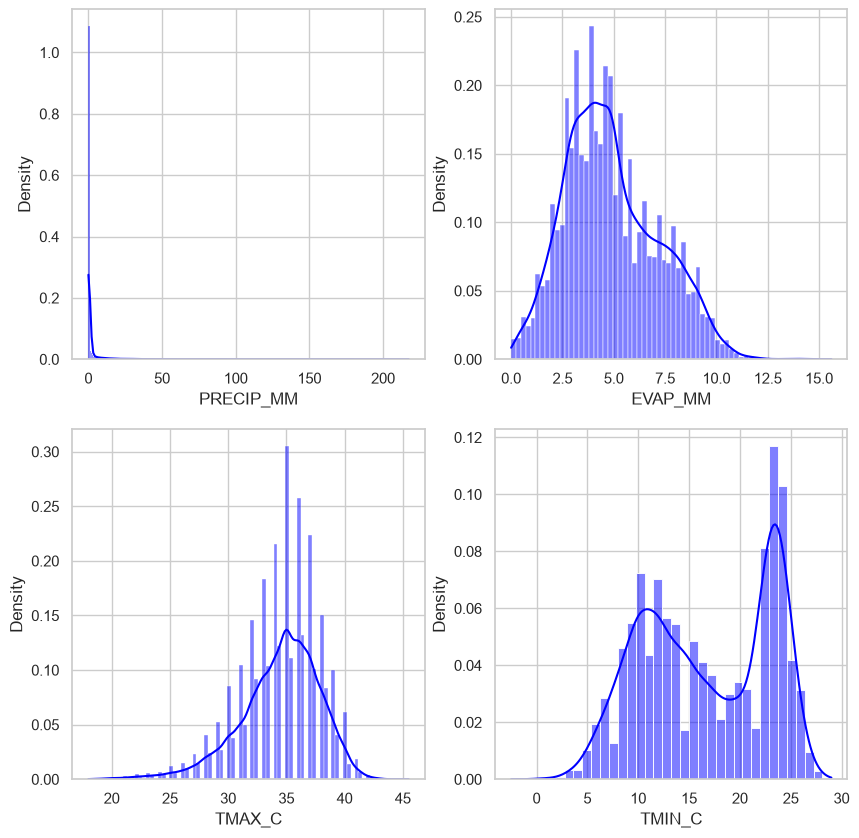

In [16]:
import matplotlib.pyplot as ptl
import seaborn as sns
f,ax = ptl.subplots(2,2, figsize=(10,10))
sns.histplot(df['PRECIP_MM'], ax=ax[0,0], kde=True, stat='density', color='blue')
sns.histplot(df['EVAP_MM'], ax=ax[0,1], kde=True, stat='density', color='blue')
sns.histplot(df['TMAX_C'], ax=ax[1,0], kde=True, stat='density', color='blue')
sns.histplot(df['TMIN_C'], ax=ax[1,1], kde=True, stat='density', color='blue')

### **MAPA DE CALOR DE CORRELACIONES**
* Se utiliza para identificar la relación entre las variables meteorológicas. Los valores cercanos a 1 indican una correlación positiva, los cercanos a -1 indican una correlación negativa y los cercanos a 0 indican poca o ninguna relación lineal.

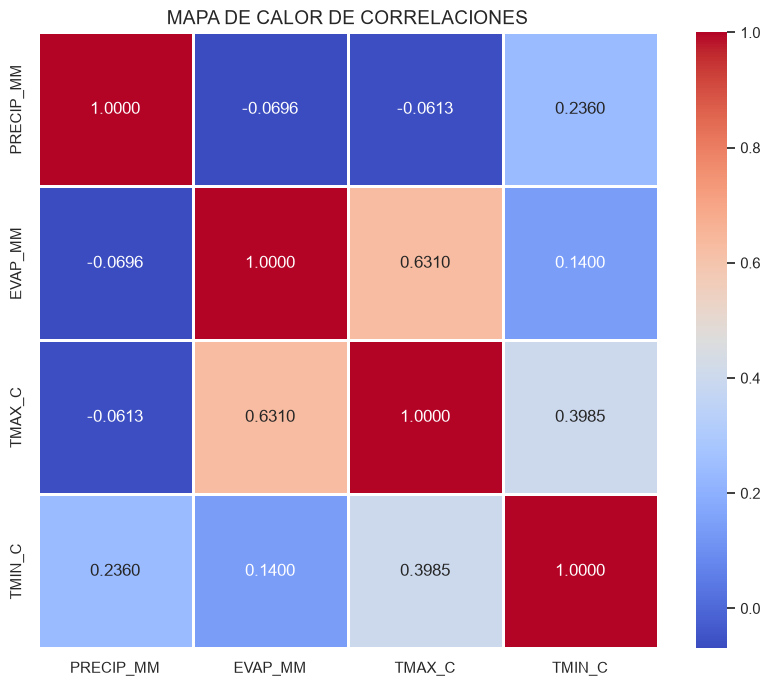

In [17]:
plt.figure(figsize=(10, 8))
matriz_correlacion = df[cols_numericas].corr()
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".4f", linewidths=1)
plt.title("MAPA DE CALOR DE CORRELACIONES", fontsize=14)
plt.show()

### **BOXPLOTS**
* Se utilizan para resumir la distribución de los datos, observar la mediana, identificar la dispersión y detectar posibles valores atípicos. Esto permite analizar el comportamiento de la precipitación, evaporación y temperaturas.

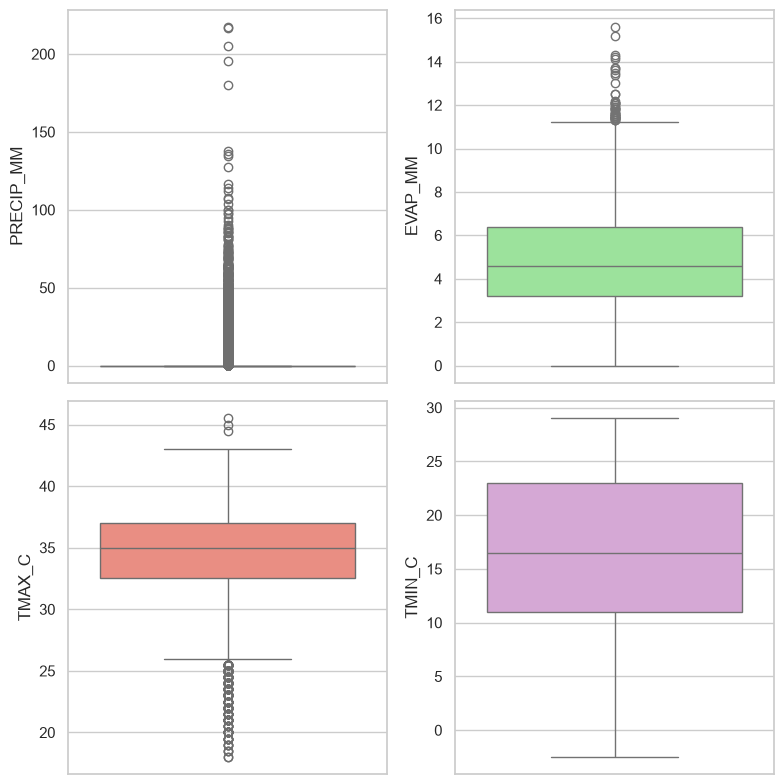

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

f, ax = plt.subplots(2, 2, figsize=(8,8))

sns.boxplot(y=df['PRECIP_MM'], ax=ax[0,0], color='skyblue')
sns.boxplot(y=df['EVAP_MM'], ax=ax[0,1], color='lightgreen')
sns.boxplot(y=df['TMAX_C'], ax=ax[1,0], color='salmon')
sns.boxplot(y=df['TMIN_C'], ax=ax[1,1], color='plum')


plt.tight_layout()
plt.show()

### **DIAGRAMA DE DISPERSIÓN**
* Se utiliza para comparar las variables numéricas entre sí mediante gráficos de dispersión. Permite observar posibles relaciones, tendencias y agrupaciones entre la precipitación, evaporación y temperaturas.

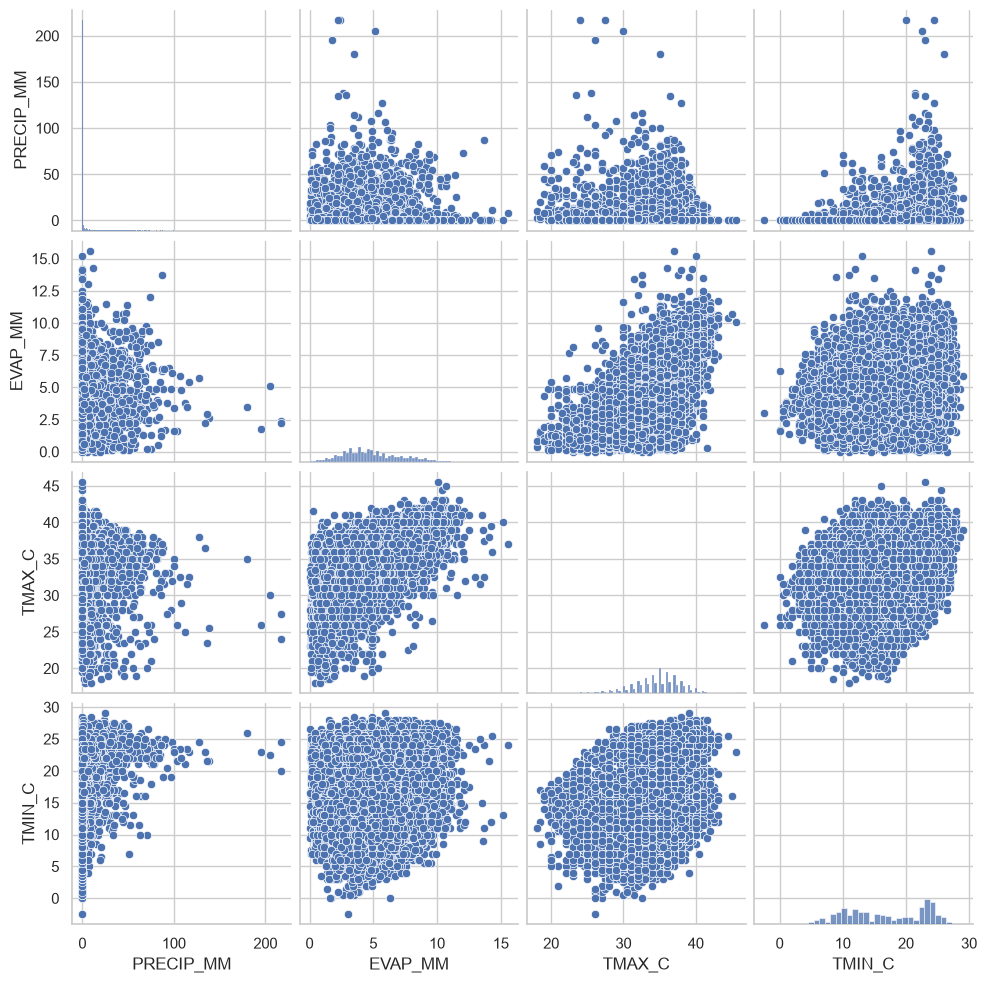

In [19]:
sns.pairplot(df, diag_kind='hist', corner=False)
plt.show()

### **DIAGRAMA DE DISPERSION POR CLASE**
* Se utiliza para analizar si existe una relación entre la temperatura mínima (TMIN_C) y la precipitación (PRECIP_MM). Cada punto representa un registro y permite observar si ambas variables presentan alguna tendencia o relación.

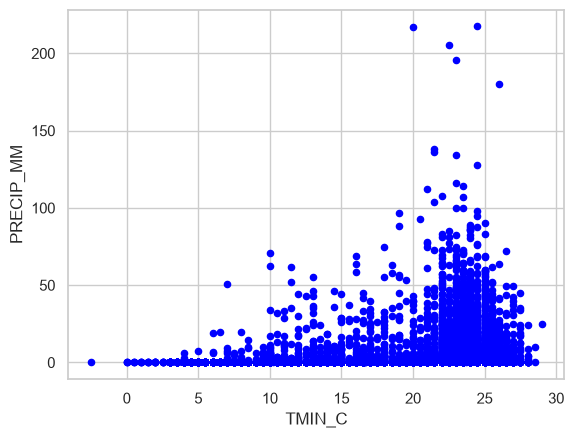

In [20]:
df.plot.scatter( y='PRECIP_MM',x='TMIN_C', color='blue')
plt.show()